# Flight Delay Analysis and Prediction (Python)

Analysis of US domestic flights 2004–2008 (ASA Data Expo 2009). See the repo README for context and results.

This is the original coursework notebook, cleaned up so it runs from top to bottom in one go (Kernel → Restart & Run All). Two things to know before reading:

- **Q5a contains target leakage.** Its models use features that are only known after departure, so their AUCs (0.94–0.98) are inflated. The leakage-free version is `src/model_v2.py`; see Q5b at the end.
- **It rebuilds the database from the raw files**, which takes about an hour and needs about 3 GB of disk. Set the `FLY_DATA_DIR` environment variable to run it in another folder, so an existing `Fly.db` is left alone.

In [1]:
import os
import warnings
import sys
import sqlite3
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib as mpl
import datetime
import plotly.express as px
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import train_test_split, GridSearchCV      
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Hide scikit-learn's notices about future versions and slow convergence; they don't change the results
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Liblinear failed to converge')

# The project's own scripts live in src/; Q5a and Q5b reuse them
sys.path.insert(0, os.path.abspath('../src'))
import model_v2

In [2]:
# Folder holding the downloaded CSVs (see data/README.md); the database is built here.
# FLY_DATA_DIR lets you build it somewhere else without touching data/Fly.db.
DATA_DIR = os.environ.get('FLY_DATA_DIR', '../data')
os.chdir(DATA_DIR)

In [3]:
try:
    os.remove('Fly.db')
except OSError:
    pass

conn = sqlite3.connect('Fly.db')

In [4]:
pd.read_csv("airports.csv").to_sql("airports", conn, if_exists="replace", index=False)
pd.read_csv("carriers.csv").to_sql("carriers", conn, if_exists="replace", index=False)
pd.read_csv("plane-data.csv").to_sql("planes", conn, if_exists="replace", index=False)

for year in range(2004, 2009):
    file_pattern = f"{year}*.csv*.bz2"
    file_list = glob.glob(file_pattern)
    
    if file_list:
        actual_file = file_list[0]
        print(f"Now processing: {actual_file}")
        
        flightdetails = pd.read_csv(actual_file, low_memory=False)
        flightdetails.to_sql("flightdetails", conn, if_exists="append", index=False)
    else:
        print(f"Warning: No file found for year {year}")

conn.close()
print("Database construction complete.")

Now processing: 2004.csv.bz2


Now processing: 2005.csv.bz2


Now processing: 2006.csv.bz2


Now processing: 2007.csv.bz2


Now processing: 2008.csv.bz2


Database construction complete.


In [5]:
# `flightdetails` is the last file loaded above (2008), not the whole database
ArrDelayModel = smf.ols('ArrDelay ~ CarrierDelay + WeatherDelay + NASDelay + SecurityDelay + LateAircraftDelay', data=flightdetails).fit()
DepDelayModel = smf.ols('DepDelay ~ CarrierDelay + WeatherDelay + NASDelay + SecurityDelay + LateAircraftDelay', data=flightdetails).fit()

print(ArrDelayModel.summary())
print(DepDelayModel.summary())

ArrDepDelay = pd.DataFrame({
'Measure': ['Arrival Delay', 'Departure Delay'],
'R2': [ArrDelayModel.rsquared, DepDelayModel.rsquared],
'Adjusted_R2': [ArrDelayModel.rsquared_adj, DepDelayModel.rsquared_adj],
'F_Statistic': [ArrDelayModel.fvalue, DepDelayModel.fvalue]
})

print(ArrDepDelay)

                            OLS Regression Results                            
Dep. Variable:               ArrDelay   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 1.525e+29
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:11:08   Log-Likelihood:             1.3047e+07
No. Observations:              584583   AIC:                        -2.609e+07
Df Residuals:                  584577   BIC:                        -2.609e+07
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          1.267e-11   9.22e-1

**What this regression does and does not show.** The five cause columns (carrier, weather, NAS, security, late aircraft) are the airline's own breakdown of each delay, so they add up to it by definition and are only filled in for delayed flights. The R² of 1.000 is therefore a consistency check on the data, not a finding about what causes delays.

Note also that `flightdetails` here is the DataFrame left in memory by the loading loop above, which is only the last file read (2008), not the full database.

In [6]:
with sqlite3.connect('Fly.db') as conn:
    query = """
    SELECT ArrDelay, COUNT(ArrDelay) AS Frequency 
    FROM flightdetails 
    WHERE ArrDelay > 0 
    GROUP BY ArrDelay
    """
    DistributionOfArrDelay = pd.read_sql(query, conn)

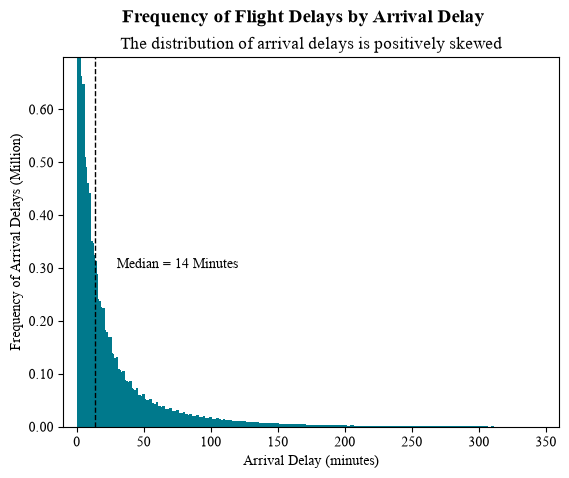

In [7]:
mpl.rcParams['font.family'] = 'Times New Roman'

plt.bar(DistributionOfArrDelay["ArrDelay"], DistributionOfArrDelay["Frequency"], color="#00798c", width=2)
plt.suptitle("Frequency of Flight Delays by Arrival Delay", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("The distribution of arrival delays is positively skewed", fontname='Times New Roman')
plt.xlabel("Arrival Delay (minutes)", fontname='Times New Roman')
plt.ylabel("Frequency of Arrival Delays (Million)", fontname='Times New Roman')
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
plt.xlim([-10, 360])
plt.ylim([0, DistributionOfArrDelay["Frequency"].max()])
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{:.2f}'.format(x*1e-6)))
plt.axvline(x=14, color='black', linewidth = 1, linestyle='--')
plt.annotate('Median = 14 Minutes', xy=(14, 14), xytext=(30, 300000), fontname='Times New Roman')
plt.show()

In [8]:
cur = conn.cursor()

cur.execute("""SELECT ArrDelay 
               FROM flightdetails 
               WHERE ArrDelay > 0""")

median_delay = np.median(cur.fetchall())

avg_delay = pd.read_sql_query("""SELECT AVG(ArrDelay) \
                                 FROM flightdetails \
                                 WHERE ArrDelay > 0""", conn)

print(median_delay)
print(avg_delay)

14.0
   AVG(ArrDelay)
0       29.98361


## Q1. Best time of the day to minimize delays

In [9]:
conn.execute("ALTER TABLE flightdetails ADD COLUMN DepTimeOfDay TEXT")

conn.commit()

conn.execute("""UPDATE flightdetails 
                SET DepTimeOfDay = 
                     CASE 
                        WHEN DepTime BETWEEN 500 AND 1159 THEN 'Morning' 
                        WHEN DepTime BETWEEN 1200 AND 1659 THEN 'Afternoon' 
                        WHEN DepTime BETWEEN 1700 AND 2059 THEN 'Evening' 
                        ELSE 'Night' 
                     END;""")

conn.commit()

In [10]:
Q1_TimeOfDay = pd.read_sql_query("""SELECT DepTimeOfDay AS Time_of_Day, 
                                    SUM(CASE WHEN ArrDelay >= 15 THEN 1 ELSE 0 END)/CAST(COUNT(ArrDelay) AS float) AS Chance_Of_Delay 
                                    FROM flightdetails
                                    GROUP BY DepTimeOfDay 
                                    ORDER BY 
                                        CASE DepTimeOfDay 
                                            WHEN 'Morning' THEN 1 
                                            WHEN 'Afternoon' THEN 2 
                                            WHEN 'Evening' THEN 3 
                                            ELSE 4 
                                        END""", conn)

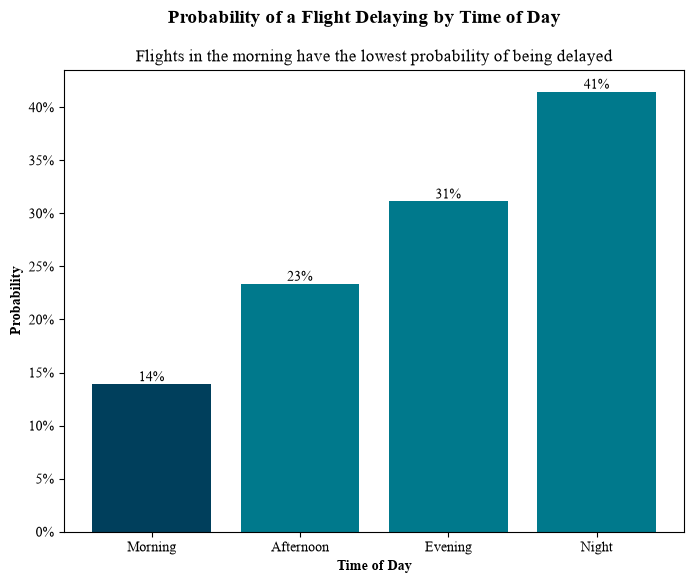

In [11]:
plt.figure(figsize=(8,6))
plt.bar(Q1_TimeOfDay['Time_of_Day'], Q1_TimeOfDay['Chance_Of_Delay'], color=['#003f5c', '#00798c', '#00798c', '#00798c'])
plt.suptitle("Probability of a Flight Delaying by Time of Day", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("Flights in the morning have the lowest probability of being delayed", fontname='Times New Roman')
plt.xlabel("Time of Day", fontweight='bold', fontname='Times New Roman')
plt.ylabel("Probability", fontweight='bold', fontname='Times New Roman')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{:.0%}'.format(x)))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
for i, val in enumerate(Q1_TimeOfDay['Chance_Of_Delay']):
    plt.text(i, val, '{:.0%}'.format(val), ha='center', va='bottom', fontname='Times New Roman', fontsize=10)
plt.show()

**Note.** This chart groups flights by their *actual* departure time. A flight that was due to leave at 19:00 but left at 22:00 is counted as "Night", so night looks worse than it is. Grouped by *scheduled* departure time, the fair comparison, the evening is the worst (30.9%) and the morning the best (15.6%). See `src/time_of_day.py` and the chart at the top of the README.

## Q1. Best day of the week to minimize delays

In [12]:
conn.execute("ALTER TABLE flightdetails ADD COLUMN FullDayOfWeek TEXT")

conn.commit()

conn.execute("""UPDATE flightdetails 
                SET FullDayOfWeek = 
                    CASE 
                        WHEN DayOfWeek IS 1 THEN 'Monday' 
                        WHEN DayOfWeek IS 2 THEN 'Tuesday' 
                        WHEN DayOfWeek IS 3 THEN 'Wednesday' 
                        WHEN DayOfWeek IS 4 THEN 'Thursday' 
                        WHEN DayOfWeek IS 5 THEN 'Friday' 
                        WHEN DayOfWeek IS 6 THEN 'Saturday' 
                        ELSE 'Sunday' 
                    END;""")

conn.commit()

In [13]:
Q1_DayOfWeek = pd.read_sql_query("""SELECT FullDayOfWeek AS Day_of_Week, 
                                    SUM(CASE WHEN ArrDelay >= 15 THEN 1 ELSE 0 END)/CAST(COUNT(ArrDelay) AS float) AS Chance_Of_Delay 
                                    FROM flightdetails 
                                    GROUP BY FullDayOfWeek 
                                    ORDER BY 
                                        CASE FullDayOfWeek 
                                        WHEN 'Monday' THEN 1 
                                        WHEN 'Tuesday' THEN 2 
                                        WHEN 'Wednesday' THEN 3 
                                        WHEN 'Thursday' THEN 4 
                                        WHEN 'Friday' THEN 5 
                                        WHEN 'Saturday' THEN 6 
                                        ELSE 7 
                                    END""", conn)

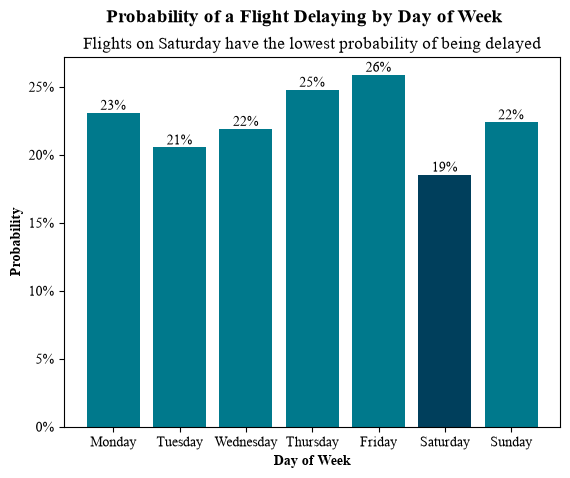

In [14]:
plt.bar(Q1_DayOfWeek['Day_of_Week'], Q1_DayOfWeek['Chance_Of_Delay'], color=['#00798c','#00798c','#00798c','#00798c','#00798c','#003f5c','#00798c'])
plt.suptitle("Probability of a Flight Delaying by Day of Week", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("Flights on Saturday have the lowest probability of being delayed", fontname='Times New Roman')
plt.xlabel("Day of Week", fontweight='bold', fontname='Times New Roman')
plt.ylabel("Probability", fontweight='bold', fontname='Times New Roman')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{:.0%}'.format(x)))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
for i, val in enumerate(Q1_DayOfWeek['Chance_Of_Delay']):
    plt.text(i, val, '{:.0%}'.format(val), ha='center', va='bottom', fontname='Times New Roman', fontsize=10)
plt.show()

## Q1. Best time of the year to fly to minimize delays

In [15]:
conn.execute("ALTER TABLE flightdetails ADD COLUMN TimeOfYear TEXT")

conn.commit()

conn.execute("""UPDATE flightdetails 
                SET TimeOfYear = 
                    CASE 
                        WHEN Month BETWEEN 3 AND 5 THEN 'Spring' 
                        WHEN Month BETWEEN 6 AND 8 THEN 'Summer' 
                        WHEN Month BETWEEN 9 AND 11 THEN 'Autumn' 
                        ELSE 'Winter' 
                    END;""")
             
conn.commit()            

In [16]:
Q1_TimeOfYear = pd.read_sql_query("""SELECT TimeOfYear AS Time_of_Year, 
                                    SUM(CASE WHEN ArrDelay >= 15 THEN 1 ELSE 0 END)/CAST(COUNT(ArrDelay) AS float) AS Chance_Of_Delay 
                                    FROM flightdetails 
                                    GROUP BY TimeOfYear 
                                    ORDER BY 
                                        CASE TimeOfYear 
                                        WHEN 'Spring' THEN 1 
                                        WHEN 'Summer' THEN 2 
                                        WHEN 'Autumn' THEN 3 
                                        ELSE 4 
                                    END""", conn)

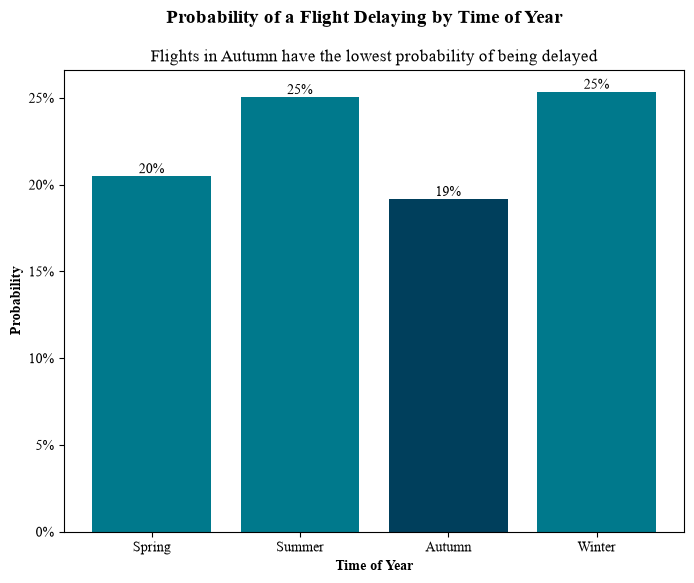

In [17]:
plt.figure(figsize=(8,6))
plt.bar(x = pd.Categorical(Q1_TimeOfYear['Time_of_Year'], categories=["Spring", "Summer", "Autumn", "Winter"], ordered=True), height=Q1_TimeOfYear['Chance_Of_Delay'], color=["#00798c", "#00798c", "#003f5c", "#00798c"])
plt.suptitle("Probability of a Flight Delaying by Time of Year", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("Flights in Autumn have the lowest probability of being delayed", fontname='Times New Roman')
plt.xlabel("Time of Year", fontweight='bold', fontname='Times New Roman')
plt.ylabel("Probability", fontweight='bold', fontname='Times New Roman')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{:.0%}'.format(x)))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
for i, val in enumerate(Q1_TimeOfYear['Chance_Of_Delay']):
    plt.text(i, val, '{:.0%}'.format(val), ha='center', va='bottom', fontname='Times New Roman', fontsize=10)
plt.show()

## Q2. Do older planes suffer more delays?

In [18]:
# One date format, yyyy-mm-dd, used by every query below
conn.execute("ALTER TABLE flightdetails ADD COLUMN CurrentDate TEXT")
conn.commit()

conn.execute("""UPDATE flightdetails
                SET CurrentDate = Year || '-' || printf('%02d', Month) || '-' || printf('%02d', DayofMonth)""")
conn.commit()

In [19]:
conn.execute("CREATE INDEX IF NOT EXISTS idx_planes_tail ON planes(tailnum)")
conn.execute("ALTER TABLE flightdetails ADD COLUMN AgeOfPlane INTEGER")
conn.commit()

# Age = flight year minus build year. Some planes have a build year of 0 or "None",
# which would give an age of about 2,004 years, so ages outside 0-60 are left blank.
conn.execute("""
UPDATE flightdetails
SET AgeOfPlane = (
    SELECT CASE WHEN flightdetails.Year - CAST(planes.year AS INT) BETWEEN 0 AND 60
                THEN flightdetails.Year - CAST(planes.year AS INT) END
    FROM planes
    WHERE planes.tailnum = flightdetails.TailNum
)
""")
conn.commit()

In [20]:
check_join = pd.read_sql_query("""
    SELECT f.TailNum, p.tailnum as PlaneTableTail, p.year as MfgYear
    FROM flightdetails f
    LEFT JOIN planes p ON f.TailNum = p.tailnum
    LIMIT 10
""", conn)
print(check_join)

  TailNum PlaneTableTail  MfgYear
0  N805UA         N805UA   1998.0
1  N851UA         N851UA   2002.0
2  N436UA         N436UA   1996.0
3  N828UA         N828UA   1999.0
4  N831UA         N831UA   2000.0
5  N834UA         N834UA   2001.0
6  N840UA         N840UA   2001.0
7  N454UA         N454UA   1999.0
8  N808UA         N808UA   1998.0
9  N832UA         N832UA   2000.0


In [21]:
query = """
SELECT 
    f.TailNum, 
    f.Year as FlightYear, 
    p.year as MfgYear,
    (f.Year - CAST(p.year AS INT)) as CalculatedAge
FROM flightdetails f
INNER JOIN planes p ON f.TailNum = p.tailnum
WHERE (f.Year - CAST(p.year AS INT)) < 0
"""
AgeAbnormalities = pd.read_sql_query(query, conn)
print(f"Found {len(AgeAbnormalities)} abnormal rows.")

Found 5825 abnormal rows.


In [22]:
# How many flights have no usable plane age (unknown plane or impossible build year)
pd.read_sql_query("SELECT COUNT(*) AS FlightsWithoutAge FROM flightdetails WHERE AgeOfPlane IS NULL", conn)

,FlightsWithoutAge
0,8124645


In [23]:
conn.execute("ALTER TABLE flightdetails ADD COLUMN AgeCategory TEXT")
conn.commit()

conn.execute("""
UPDATE flightdetails
SET AgeCategory =
    CASE
        WHEN AgeOfPlane IS NULL THEN 'Unknown'
        WHEN AgeOfPlane <= 10 THEN 'New Aircraft'
        WHEN AgeOfPlane <= 20 THEN 'Standard Aircraft'
        ELSE 'Old Aircraft'
    END
""")
conn.commit()

In [24]:
check_counts = pd.read_sql_query("SELECT AgeCategory, COUNT(*) FROM flightdetails GROUP BY AgeCategory", conn)
print(check_counts)

         AgeCategory  COUNT(*)
0       New Aircraft  15074712
1       Old Aircraft   1445656
2  Standard Aircraft   6609207
3            Unknown   8124645


In [25]:
Q2_AgeOfPlane = pd.read_sql("""SELECT AgeCategory AS Age_Category, SUM(CASE WHEN ArrDelay >= 15 THEN 1 ELSE 0 END)/CAST(COUNT(ArrDelay) AS float) AS Chance_Of_Delay
                               FROM flightdetails
                               WHERE AgeCategory <> 'Unknown'
                               GROUP BY AgeCategory
                               ORDER BY 
                                CASE WHEN AgeCategory = 'New Aircraft' THEN 1
                                    WHEN AgeCategory = 'Standard Aircraft' THEN 2
                                    WHEN AgeCategory = 'Old Aircraft' THEN 3
                                    ELSE 4
                                END""", conn)

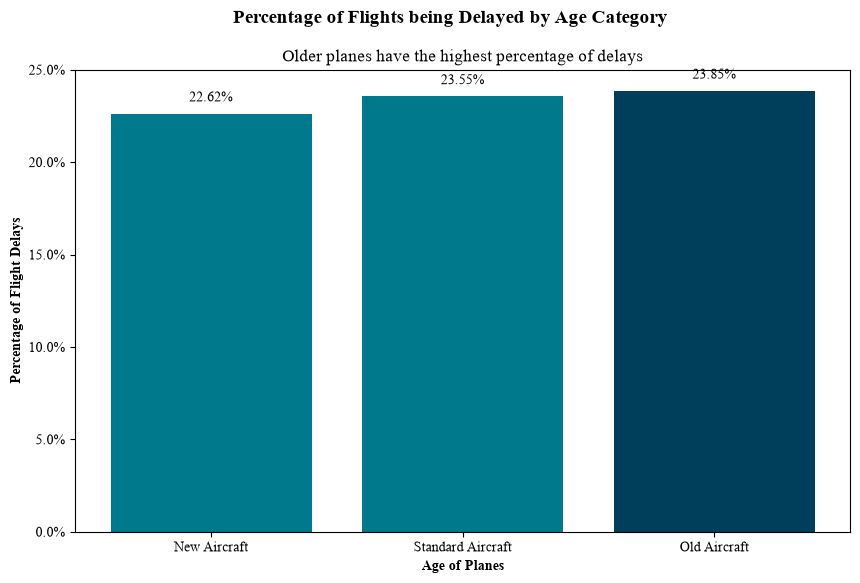

In [26]:
categories = ["New Aircraft", "Standard Aircraft", "Old Aircraft"]
Q2_AgeOfPlane['Age_Category'] = pd.Categorical(Q2_AgeOfPlane['Age_Category'], 
                                               categories=categories, 
                                               ordered=True)
df_plot = Q2_AgeOfPlane.sort_values('Age_Category')

fig, ax = plt.subplots(figsize=(10, 6))

x_pos = range(len(df_plot))
ax.bar(x_pos, df_plot['Chance_Of_Delay'], color=['#00798c', '#00798c', '#003f5c'])

plt.suptitle('Percentage of Flights being Delayed by Age Category', fontweight='bold', fontsize=14, fontname='Times New Roman')
plt.title('Older planes have the highest percentage of delays', fontname='Times New Roman')
plt.xlabel('Age of Planes', fontweight='bold', fontname='Times New Roman')
plt.ylabel('Percentage of Flight Delays', fontweight='bold', fontname='Times New Roman')

ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1))
plt.xticks(x_pos, df_plot['Age_Category'], fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
plt.ylim([0, 0.25])

for i, v in enumerate(df_plot['Chance_Of_Delay']):
    label = "{:.2%}".format(float(v))
    ax.text(i, float(v) + 0.005, label, ha='center', va='bottom', fontname='Times New Roman')

plt.show()

In [27]:
Q2_AgeOfPlane.head()

,Age_Category,Chance_Of_Delay
0,New Aircraft,0.226231
1,Standard Aircraft,0.235547
2,Old Aircraft,0.238546


In [28]:
Q2_AgeOfPlaneDelays = pd.read_sql("""SELECT AgeCategory AS Age_Category, ArrDelay AS Duration_Of_Delays
                                     FROM flightdetails
                                     WHERE AgeCategory <> 'Unknown' AND ArrDelay >= 15
                                     ORDER BY 
                                        CASE WHEN AgeCategory = 'New Aircraft' THEN 1
                                            WHEN AgeCategory = 'Standard Aircraft' THEN 2
                                            WHEN AgeCategory = 'Old Aircraft' THEN 3
                                            ELSE 4
                                        END""", conn)

C:\Users\matti\AppData\Local\Temp\ipykernel_26172\4052345500.py:4: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  ax = sns.violinplot(


findfont: Failed to find font weight semibold for Times New Roman, now using 700.


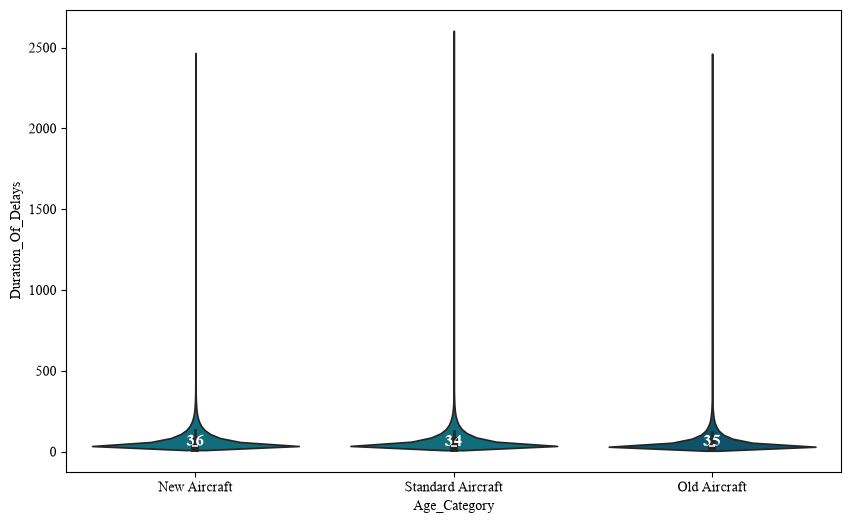

In [29]:
medians = Q2_AgeOfPlaneDelays.groupby(['Age_Category'])['Duration_Of_Delays'].median()

plt.figure(figsize=(10, 6))
ax = sns.violinplot(
    data=Q2_AgeOfPlaneDelays, 
    x='Age_Category', 
    y='Duration_Of_Delays', 
    hue='Age_Category', 
    legend=False,
    palette=['#00798c', '#00798c', '#005b7a', '#999999'],
    inner='box'
)

pos = range(len(medians))
for tick in pos:
    median_val = medians.iloc[tick]
    plt.text(
        tick, 
        median_val + 1, 
        str(int(median_val)), 
        horizontalalignment='center', 
        size='large', 
        color='white', 
        weight='semibold', 
        fontname='Times New Roman'
    )

plt.show()

## Q3. Number of people flying between different locations over time

In [30]:
Q3_MonthlyFrequencyIntrastate = pd.read_sql("""SELECT substr(flightdetails.CurrentDate, 1, 7) AS Month, COUNT(*) as Frequency
                                               FROM flightdetails
                                               INNER JOIN airports ON flightdetails.Dest = airports.iata
                                               INNER JOIN airports a ON flightdetails.Origin = a.iata
                                               WHERE airports.state = a.state
                                               GROUP BY substr(flightdetails.CurrentDate, 1, 7)
                                               ORDER BY substr(flightdetails.CurrentDate, 1, 7)""", conn)

In [31]:
Q3_MonthlyFrequencyInterstate = pd.read_sql("""SELECT substr(flightdetails.CurrentDate, 1, 7) AS Month, COUNT(*) as Frequency
                                               FROM flightdetails
                                               INNER JOIN airports ON flightdetails.Dest = airports.iata
                                               INNER JOIN airports a ON flightdetails.Origin = a.iata
                                               WHERE airports.state <> a.state
                                               GROUP BY substr(flightdetails.CurrentDate, 1, 7)
                                               ORDER BY substr(flightdetails.CurrentDate, 1, 7)""", conn)

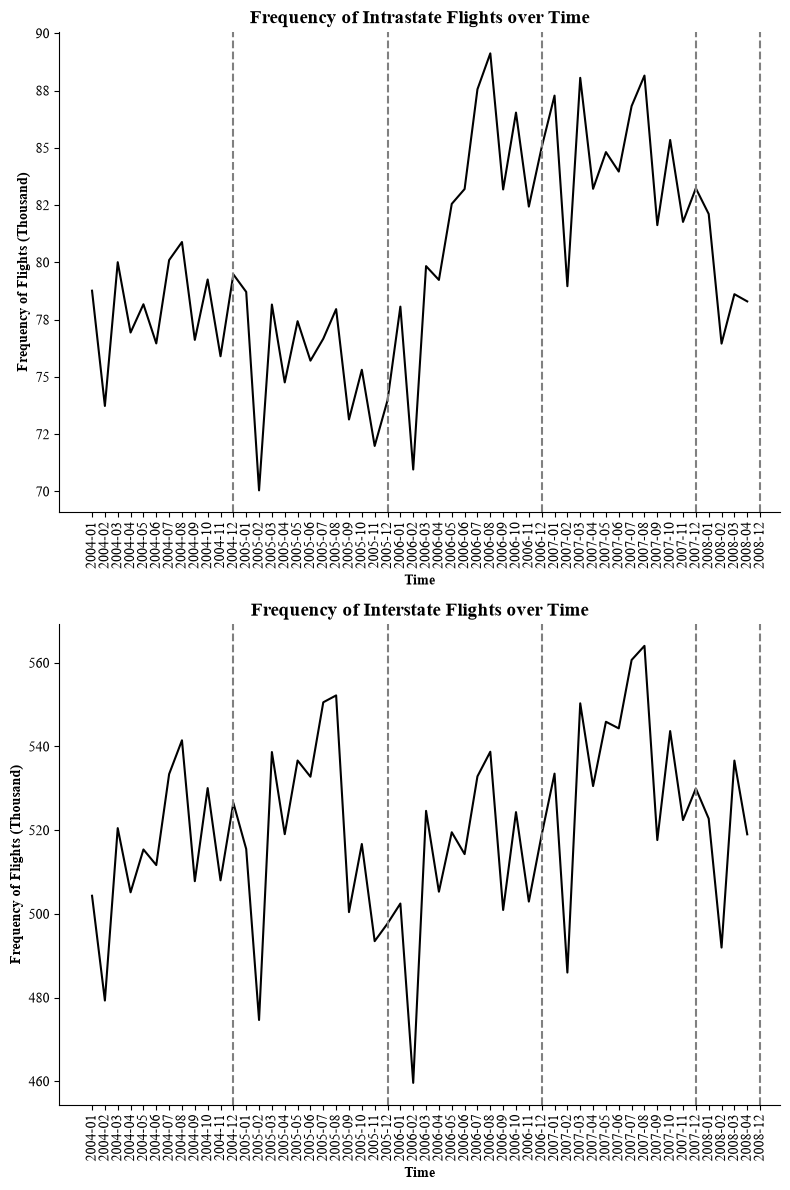

In [32]:
fig, axs = plt.subplots(nrows=2, figsize=(8, 12))

sns.lineplot(data=Q3_MonthlyFrequencyIntrastate, x='Month', y='Frequency', ax=axs[0], color='black')
sns.despine(ax=axs[0])
axs[0].set_title('Frequency of Intrastate Flights over Time', fontweight='bold', fontsize=14, fontname='Times New Roman')
axs[0].set_ylabel('Frequency of Flights (Thousand)', fontweight='bold', fontname='Times New Roman')
axs[0].set_xlabel('Time', fontweight='bold', fontname='Times New Roman')
axs[0].tick_params(axis='x', rotation=90)
axs[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    axs[0].axvline(x=xc, color='grey', linestyle='--')
    
sns.lineplot(data=Q3_MonthlyFrequencyInterstate, x='Month', y='Frequency', ax=axs[1], color='black')
sns.despine(ax=axs[1])
axs[1].set_title('Frequency of Interstate Flights over Time', fontweight='bold', fontsize=14, fontname='Times New Roman')
axs[1].set_ylabel('Frequency of Flights (Thousand)', fontweight='bold', fontname='Times New Roman')
axs[1].set_xlabel('Time', fontweight='bold', fontname='Times New Roman')
axs[1].tick_params(axis='x', rotation=90)
axs[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    axs[1].axvline(x=xc, color='grey', linestyle='--')   
    
plt.tight_layout()
plt.show()

In [33]:
Q3_MonthlyFrequencyOfIntrastateByState = pd.read_sql("""SELECT airports.state, substr(flightdetails.CurrentDate, 1, 7) AS Month, COUNT() as Frequency, COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY substr(flightdetails.CurrentDate, 1, 7)) AS FLOAT) AS Percentage
                                                        FROM flightdetails
                                                        INNER JOIN airports ON flightdetails.Dest = airports.iata
                                                        INNER JOIN airports a ON flightdetails.Origin = a.iata
                                                        WHERE airports.state = a.state
                                                        GROUP BY airports.state, substr(flightdetails.CurrentDate, 1, 7)
                                                        ORDER BY substr(flightdetails.CurrentDate, 1, 7)""", conn)

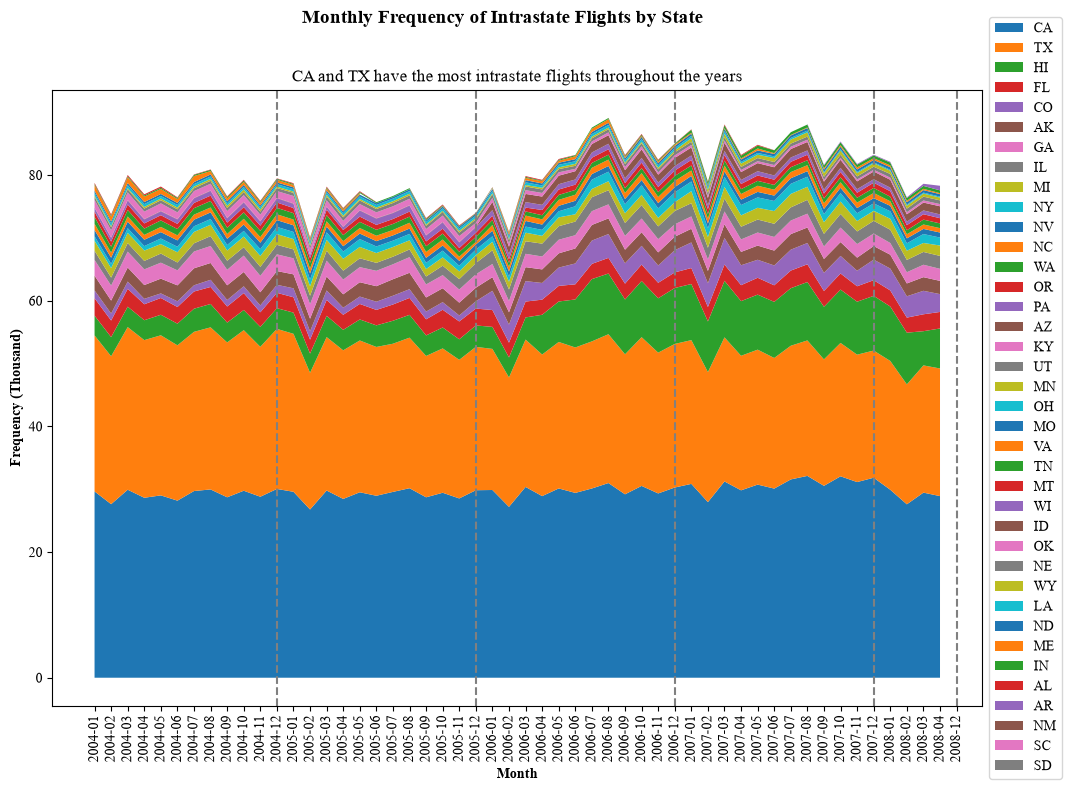

In [34]:
df = Q3_MonthlyFrequencyOfIntrastateByState.pivot_table(index='Month', columns='state', values='Frequency', aggfunc='sum')

state_order = df.sum().sort_values(ascending=False).index
df = df[state_order]
df_cumulative = df.cumsum(axis=1)
fig, ax = plt.subplots(figsize=(12,8))
for state in df.columns:
    ax.fill_between(df.index, df_cumulative[state] - df[state], df_cumulative[state], label=state, linewidth=0.5)
fig.suptitle('Monthly Frequency of Intrastate Flights by State', fontsize=14, fontweight='bold', fontname='Times New Roman')
ax.set_title('CA and TX have the most intrastate flights throughout the years', fontname='Times New Roman')
ax.set_xlabel('Month', fontweight='bold', fontname='Times New Roman')
ax.set_ylabel('Frequency (Thousand)', fontweight='bold', fontname='Times New Roman')
ax.tick_params(axis='x', rotation=90)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    ax.axvline(x=xc, color='grey', linestyle='--')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman') 
plt.show()

In [35]:
Q3_MonthlyFrequencyOfInboundByState = pd.read_sql_query("""SELECT airports.state, substr(flightdetails.CurrentDate, 1, 7) AS Month, COUNT() as Frequency, COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY substr(flightdetails.CurrentDate, 1, 7)) AS FLOAT) AS Percentage
                                                           FROM flightdetails
                                                           INNER JOIN airports ON flightdetails.Dest = airports.iata
                                                           INNER JOIN airports a ON flightdetails.Origin = a.iata
                                                           WHERE airports.state <> a.state
                                                           GROUP BY airports.state, substr(flightdetails.CurrentDate, 1, 7)
                                                           ORDER BY substr(flightdetails.CurrentDate, 1, 7)""", conn)

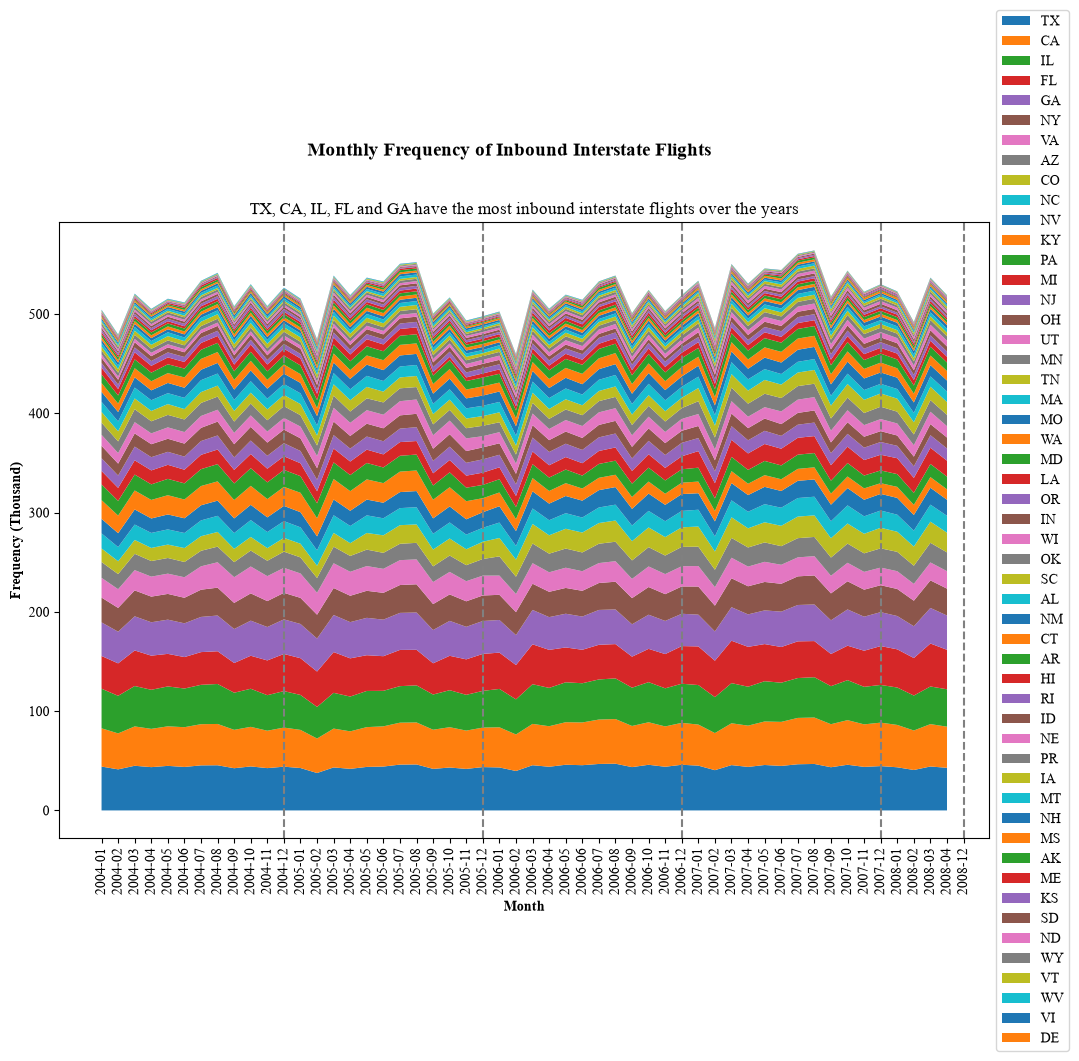

In [36]:
df = Q3_MonthlyFrequencyOfInboundByState.pivot_table(index='Month', columns='state', values='Frequency', aggfunc='sum')

state_order = df.sum().sort_values(ascending=False).index
df = df[state_order]
df_cumulative = df.cumsum(axis=1)
fig, ax = plt.subplots(figsize=(12,8))
for state in df.columns:
    ax.fill_between(df.index, df_cumulative[state] - df[state], df_cumulative[state], label=state, linewidth=0.5)
fig.suptitle('Monthly Frequency of Inbound Interstate Flights', fontsize=14, fontweight='bold', fontname='Times New Roman')
ax.set_title('TX, CA, IL, FL and GA have the most inbound interstate flights over the years', fontname='Times New Roman')
ax.set_xlabel('Month', fontweight='bold', fontname='Times New Roman')
ax.set_ylabel('Frequency (Thousand)', fontweight='bold', fontname='Times New Roman')
ax.tick_params(axis='x', rotation=90)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    ax.axvline(x=xc, color='grey', linestyle='--')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman') 
plt.show()

In [37]:
years = ["2004", "2005", "2006", "2007", "2008"]

for year in years:
    yearly_inbound_frequency = f"""SELECT airports.state, Year AS Year, COUNT() as Frequency,
                                   COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY flightdetails.Year) AS FLOAT) AS Percentage
                                   FROM flightdetails
                                   INNER JOIN airports ON flightdetails.Dest = airports.iata
                                   INNER JOIN airports a ON flightdetails.Origin = a.iata
                                   WHERE airports.state <> a.state AND Year = '{year}'
                                   GROUP BY airports.state, flightdetails.Year
                                   ORDER BY flightdetails.Year"""
    globals()[f"Q3_{year}FrequencyOfInboundState"] = pd.read_sql(yearly_inbound_frequency, conn)

In [38]:
fig = px.choropleth(Q3_2004FrequencyOfInboundState, 
                    locations='state', 
                    locationmode='USA-states',
                    color='Percentage',
                    scope='usa',
                    color_continuous_scale='Blues',
                    range_color=[0, 0.1],
                    title='Percentage of Inbound Flight Frequency per State for 2004')

fig.update_layout(title_font=dict(size=15, family='Times New Roman'),
                  font=dict(family='Times New Roman', size=10),
                  coloraxis_colorbar=dict(title=dict(text='Percentage of Flights'), 
                                          tickformat=".0%"),
                  geo=dict(scope='usa',projection=dict(type='albers usa')))

fig.show()

In [39]:
fig = px.choropleth(Q3_2008FrequencyOfInboundState, 
                    locations='state', 
                    locationmode='USA-states',
                    color='Percentage',
                    scope='usa',
                    color_continuous_scale='Blues',
                    range_color=[0, 0.1],
                    title='Percentage of Inbound Flight Frequency per State for 2008')

fig.update_layout(title_font=dict(size=15, family='Times New Roman'),
                  font=dict(family='Times New Roman', size=10),
                  coloraxis_colorbar=dict(title=dict(text='Percentage of Flights'), 
                                          tickformat=".0%"),
                  geo=dict(scope='usa',projection=dict(type='albers usa')))

fig.show()

In [40]:
Q3_MonthlyFrequencyOfOutboundByState = pd.read_sql_query("""SELECT a.state, substr(flightdetails.CurrentDate, 1, 7) AS Month, COUNT() as Frequency, COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY substr(flightdetails.CurrentDate, 1, 7)) AS FLOAT) AS Percentage
                                                           FROM flightdetails
                                                           INNER JOIN airports ON flightdetails.Dest = airports.iata
                                                           INNER JOIN airports a ON flightdetails.Origin = a.iata
                                                           WHERE airports.state <> a.state
                                                           GROUP BY a.state, substr(flightdetails.CurrentDate, 1, 7)
                                                           ORDER BY substr(flightdetails.CurrentDate, 1, 7)""", conn)

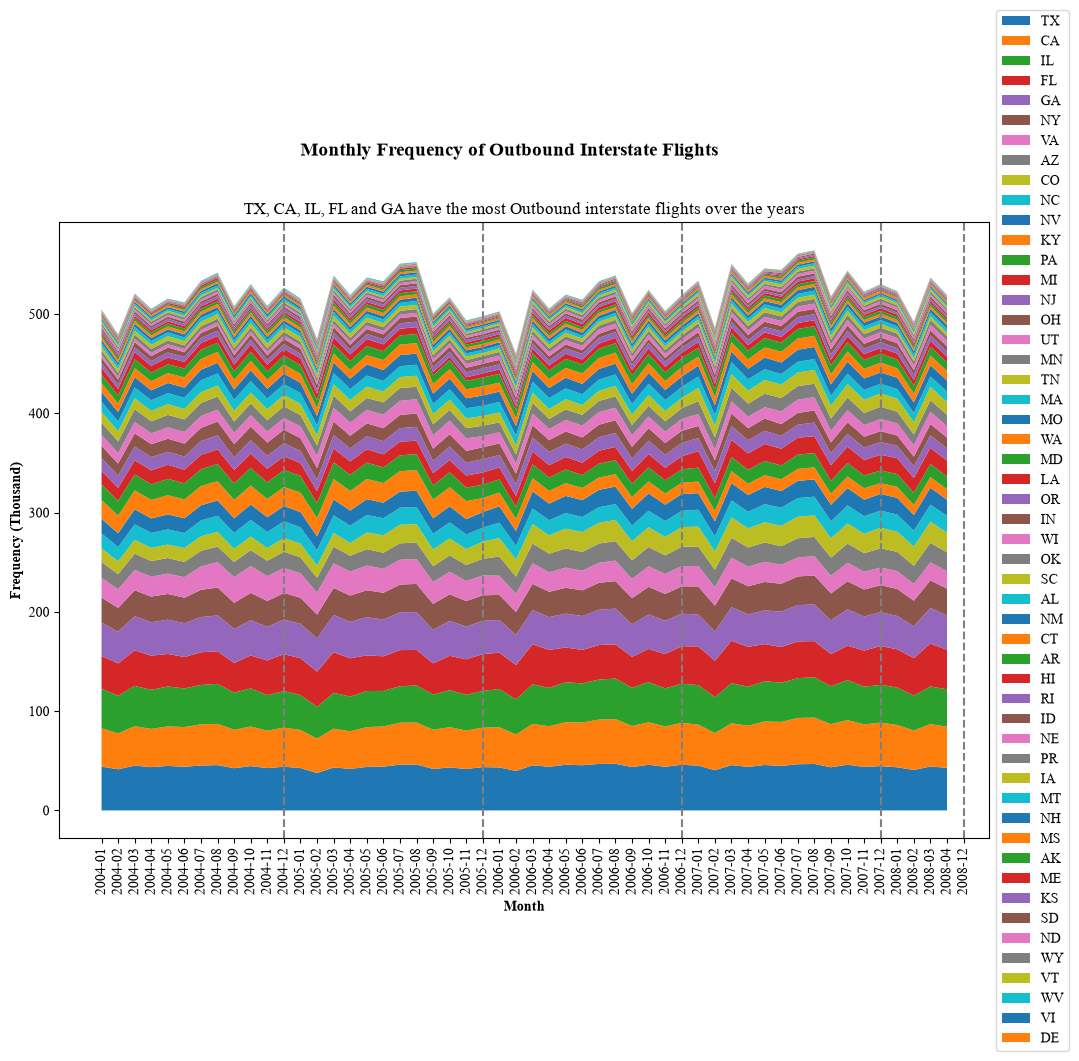

In [41]:
df = Q3_MonthlyFrequencyOfOutboundByState.pivot_table(index='Month', columns='state', values='Frequency', aggfunc='sum')

state_order = df.sum().sort_values(ascending=False).index
df = df[state_order]
df_cumulative = df.cumsum(axis=1)
fig, ax = plt.subplots(figsize=(12,8))
for state in df.columns:
    ax.fill_between(df.index, df_cumulative[state] - df[state], df_cumulative[state], label=state, linewidth=0.5)
fig.suptitle('Monthly Frequency of Outbound Interstate Flights', fontsize=14, fontweight='bold', fontname='Times New Roman')
ax.set_title('TX, CA, IL, FL and GA have the most Outbound interstate flights over the years', fontname='Times New Roman')
ax.set_xlabel('Month', fontweight='bold', fontname='Times New Roman')
ax.set_ylabel('Frequency (Thousand)', fontweight='bold', fontname='Times New Roman')
ax.tick_params(axis='x', rotation=90)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    ax.axvline(x=xc, color='grey', linestyle='--')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman') 
plt.show()

In [42]:
years = ["2004", "2005", "2006", "2007", "2008"]

for year in years:
    yearly_outbound_frequency = f"""SELECT a.state, Year AS Year, COUNT() as Frequency,
                                   COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY flightdetails.Year) AS FLOAT) AS Percentage
                                   FROM flightdetails
                                   INNER JOIN airports ON flightdetails.Dest = airports.iata
                                   INNER JOIN airports a ON flightdetails.Origin = a.iata
                                   WHERE airports.state <> a.state AND Year = '{year}'
                                   GROUP BY a.state, flightdetails.Year
                                   ORDER BY flightdetails.Year"""
    globals()[f"Q3_{year}FrequencyOfOutboundState"] = pd.read_sql(yearly_outbound_frequency, conn)

In [43]:
fig = px.choropleth(Q3_2004FrequencyOfOutboundState, 
                    locations='state', 
                    locationmode='USA-states',
                    color='Percentage',
                    scope='usa',
                    color_continuous_scale='Blues',
                    range_color=[0, 0.1],
                    title='Percentage of Outbound Flight Frequency per State for 2004')

fig.update_layout(title_font=dict(size=15, family='Times New Roman'),
                  font=dict(family='Times New Roman', size=10),
                  coloraxis_colorbar=dict(title=dict(text='Percentage of Flights'), 
                                          tickformat=".0%"),
                  geo=dict(scope='usa',projection=dict(type='albers usa')))

fig.show()

In [44]:
fig = px.choropleth(Q3_2008FrequencyOfOutboundState, 
                    locations='state', 
                    locationmode='USA-states',
                    color='Percentage',
                    scope='usa',
                    color_continuous_scale='Blues',
                    range_color=[0, 0.1],
                    title='Percentage of Outbound Flight Frequency per State for 2008')

fig.update_layout(title_font=dict(size=15, family='Times New Roman'),
                  font=dict(family='Times New Roman', size=10),
                  coloraxis_colorbar=dict(title=dict(text='Percentage of Flights'), 
                                          tickformat=".0%"),
                  geo=dict(scope='usa',projection=dict(type='albers usa')))

fig.show()

## Q4. Detecting cascading delays

A **cascading delay** is a late arrival that makes the same plane's *next* flight leave late. The original version matched a late flight with *every* later flight of that plane on the same day, so one late arrival could be counted several times. This version only looks at the next flight, using `LEAD()` (which reads the following row in time order). Cancelled flights and placeholder tail numbers (such as "0" or "UNKNOW") are left out, because they are not real legs of one plane.

In [45]:
# Every query in Q4 looks up a plane's flights on one day
conn.execute("CREATE INDEX IF NOT EXISTS idx_plane_day ON flightdetails (TailNum, CurrentDate, CRSDepTime)")
conn.commit()

In [46]:
next_leg = """
WITH legs AS (
    SELECT TailNum, CurrentDate, Origin, Dest, CRSArrTime, ArrDelay,
           LEAD(Origin) OVER plane_day AS NextOrigin,
           LEAD(CRSDepTime) OVER plane_day AS NextCRSDepTime,
           LEAD(DepDelay) OVER plane_day AS NextDepDelay,
           LEAD(ArrDelay) OVER plane_day AS NextArrDelay,
           LEAD(LateAircraftDelay) OVER plane_day AS NextLateAircraftDelay
    FROM flightdetails
    WHERE Cancelled = 0 AND TailNum NOT IN ('0', '000000', 'UNKNOW', 'NA', '')
    WINDOW plane_day AS (PARTITION BY TailNum, CurrentDate ORDER BY CRSDepTime)
),
cascades AS (
    SELECT * FROM legs
    WHERE Dest = NextOrigin           -- the plane flies on from where it landed
      AND ArrDelay > 0                -- it landed late
      AND NextDepDelay > 0            -- its next flight left late
      AND NextArrDelay > 0            -- and arrived late
      AND NextLateAircraftDelay > 0   -- and the airline blamed the late incoming plane
)
"""

Q4_FrequencyOfCascadingDelays = pd.read_sql(next_leg + """
SELECT (SELECT COUNT(*) FROM legs WHERE ArrDelay > 0 AND Dest = NextOrigin) AS LateArrivalsWithANextFlight,
       COUNT(*) AS CascadingDelays
FROM cascades""", conn)
Q4_FrequencyOfCascadingDelays['ShareThatCascaded'] = (Q4_FrequencyOfCascadingDelays['CascadingDelays']
                                                      / Q4_FrequencyOfCascadingDelays['LateArrivalsWithANextFlight'])
Q4_FrequencyOfCascadingDelays

,LateArrivalsWithANextFlight,CascadingDelays,ShareThatCascaded
0,10301409,2810753,0.272851


In [47]:
# A few examples, to check the matches look right
Q4_EntriesOfCascadingDelays = pd.read_sql_query(next_leg + """
SELECT TailNum, CurrentDate, Origin, Dest, CRSArrTime, ArrDelay,
       NextCRSDepTime, NextDepDelay, NextArrDelay, NextLateAircraftDelay
FROM cascades
LIMIT 5""", conn)

Q4_EntriesOfCascadingDelays

,TailNum,CurrentDate,Origin,Dest,CRSArrTime,ArrDelay,NextCRSDepTime,NextDepDelay,NextArrDelay,NextLateAircraftDelay
0,80009E,2007-01-04,MSP,OKC,1522,22.0,1550,22.0,29.0,22
1,80009E,2007-01-10,MSP,BIS,1025,28.0,1055,18.0,26.0,18
2,80009E,2007-01-14,MSP,STL,1205,44.0,1245,33.0,28.0,28
3,80009E,2007-01-15,RST,MSP,605,73.0,700,49.0,64.0,49
4,80009E,2007-01-21,DTW,STL,1258,32.0,1330,23.0,15.0,15


## Q5a. Coursework model (contains target leakage)

The features below include `DepTime`, `DepDelay`, `AirTime`, `TaxiIn` and `TaxiOut`. These are only known once the flight has left (or landed), and departure delay almost decides whether the arrival is 15+ minutes late. That is **target leakage**: the models score AUC 0.94–0.98 because they are partly told the answer. A sign of it is that plain logistic regression does about as well as random forest.

The split is also random rather than by time, so the models train on flights from the same days they are tested on. Both problems are fixed in Q5b.

In [48]:
# A fixed sample of about 100,000 flights (0.32% of 31 million), picked by the same hash as
# src/model_v2.py. The original used ORDER BY RANDOM(), which gives different flights every run.
conn.create_function("in_sample", 1, lambda rowid: model_v2.in_sample(rowid, 0.32, 42), deterministic=True)
LearningSample = pd.read_sql_query("""SELECT Year, Month, DayofMonth, DayofWeek, DepTime, CRSDepTime, AirTime, Distance, DepDelay, TaxiIn, TaxiOut,
                                      CASE WHEN ArrDelay < 15 THEN 0 ELSE 1 END AS Delayed
                                      FROM flightdetails
                                      WHERE in_sample(rowid) = 1""", conn)

In [49]:
LearningSample.head()

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,AirTime,Distance,DepDelay,TaxiIn,TaxiOut,Delayed
0,2004,1,26,1,NaN,1845,NaN,334,NaN,0.0,0.0,1
1,2004,1,30,5,1204.0,1205,231.0,1723,-1.0,2.0,14.0,0
2,2004,1,16,5,1939.0,1940,249.0,1835,-1.0,4.0,62.0,1
3,2004,1,30,5,1013.0,1015,154.0,1199,-2.0,6.0,20.0,0
4,2004,1,31,6,646.0,650,89.0,550,-4.0,4.0,12.0,0


In [50]:
features = ['Year', 'Month', 'DayofMonth', 'DayOfWeek', 'DepTime', 'CRSDepTime', 'AirTime', 'Distance', 'DepDelay', 'TaxiIn', 'TaxiOut']
X = LearningSample[features].copy()
y = LearningSample['Delayed'].copy()

In [51]:
y.head()

0    1
1    0
2    1
3    0
4    0
Name: Delayed, dtype: int64

In [52]:
numerical_features = ['DepTime', 'CRSDepTime', 'AirTime', 'Distance', 'DepDelay', 'TaxiIn', 'TaxiOut']

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer()),
    ('scaler', StandardScaler())])

categorical_features = ['Year', 'Month', 'DayofMonth', 'DayOfWeek']

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer()),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

data_transformer = ColumnTransformer(
    transformers=[
        ('numerical', numerical_transformer, numerical_features),
        ('categorical', categorical_transformer, categorical_features)])

In [53]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=1)

In [54]:
param_grid = {
    'data_transformer__numerical__imputer__strategy': ['mean', 'median'],
    'data_transformer__categorical__imputer__strategy': ['constant','most_frequent']
}

In [55]:
pipe_lr = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_lr', LogisticRegression(max_iter=10000, penalty=None)) 
])

param_grid = {
    'pipe_lr__solver': ['lbfgs', 'saga']
}

grid_lr = GridSearchCV(pipe_lr, param_grid=param_grid)
grid_lr.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...nalty=None))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pipe_lr__solver': ['lbfgs', 'saga']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information printed during fi

In [56]:
pipe_gdb = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_gdb', GradientBoostingClassifier(random_state=2))
])

param_grid = {
    'pipe_gdb__n_estimators': [100, 150],
    'pipe_gdb__learning_rate': [0.1, 0.05],
    'pipe_gdb__max_depth': [3, 5]
}

grid_gdb = GridSearchCV(pipe_gdb, param_grid=param_grid, n_jobs=-1)
grid_gdb.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=2))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pipe_gdb__learning_rate': [0.1, 0.05], 'pipe_gdb__max_depth': [3, 5], 'pipe_gdb__n_estimators': [100, 150]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: 

In [57]:
pipe_plr = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_plr', LogisticRegression(penalty='l1', max_iter=10000, tol=0.01, solver='saga'))
])

param_grid = {
    'pipe_plr__C': [0.1, 1.0, 10.0]
}

grid_plr = GridSearchCV(pipe_plr, param_grid=param_grid)
grid_plr.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... tol=0.01))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pipe_plr__C': [0.1, 1.0, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, 

In [58]:
pipe_tree = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_tree', DecisionTreeClassifier(random_state=0))
])

param_grid = {
    'pipe_tree__max_depth': [5, 10, 20],
    'pipe_tree__min_samples_split': [2, 10],
    'pipe_tree__criterion': ['gini', 'entropy']
}

grid_tree = GridSearchCV(pipe_tree, param_grid=param_grid)
grid_tree.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pipe_tree__criterion': ['gini', 'entropy'], 'pipe_tree__max_depth': [5, 10, ...], 'pipe_tree__min_samples_split': [2, 10]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"

In [59]:
pipe_rf = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_rf', RandomForestClassifier(random_state=0))
])

param_grid = {
    'pipe_rf__n_estimators': [100, 200],
    'pipe_rf__max_depth': [10, 20],
    'pipe_rf__min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(pipe_rf, param_grid=param_grid, n_jobs=-1)
grid_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pipe_rf__max_depth': [10, 20], 'pipe_rf__min_samples_split': [2, 5], 'pipe_rf__n_estimators': [100, 200]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: in

In [60]:
pipe_svm = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_svm', LinearSVC(random_state=0, max_iter=10000, tol=0.01))
])

param_grid = {
    'pipe_svm__C': [0.1, 1.0, 10.0],
    'pipe_svm__loss': ['hinge', 'squared_hinge']
}

grid_svm = GridSearchCV(pipe_svm, param_grid=param_grid)
grid_svm.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step..., tol=0.01))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pipe_svm__C': [0.1, 1.0, ...], 'pipe_svm__loss': ['hinge', 'squared_hinge']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the 

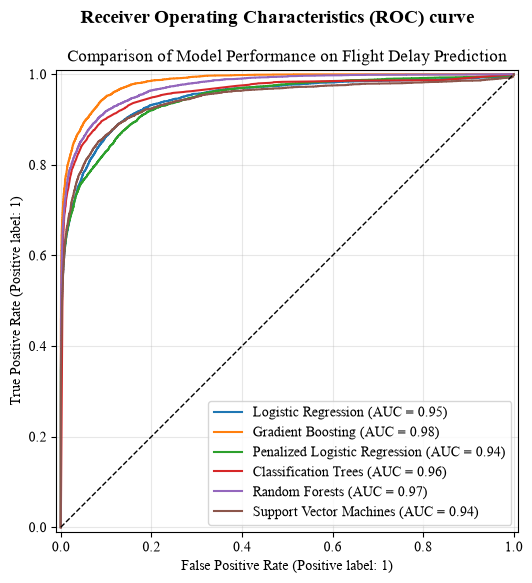

In [61]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(grid_lr, X_test, y_test, ax=ax, name='Logistic Regression')
RocCurveDisplay.from_estimator(grid_gdb, X_test, y_test, ax=ax, name='Gradient Boosting')
RocCurveDisplay.from_estimator(grid_plr, X_test, y_test, ax=ax, name='Penalized Logistic Regression')
RocCurveDisplay.from_estimator(grid_tree, X_test, y_test, ax=ax, name='Classification Trees')
RocCurveDisplay.from_estimator(grid_rf, X_test, y_test, ax=ax, name='Random Forests')
RocCurveDisplay.from_estimator(grid_svm, X_test, y_test, ax=ax, name='Support Vector Machines')

plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.suptitle("Receiver Operating Characteristics (ROC) curve", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("Comparison of Model Performance on Flight Delay Prediction", fontname='Times New Roman')
plt.grid(alpha=0.3)
plt.show()

## Q5b. Leakage-free model (v2)

This section imports and runs the functions in `src/model_v2.py`. It uses only what is known before departure: scheduled departure and arrival hour, scheduled flight time, distance, month, weekday, carrier, origin, destination and aircraft age. It trains on 2004–2007 and tests on 2008 (the 2008 file covers January to April). The leaky feature set is run alongside so the gap is visible.

The sample is fixed by `pct` and `seed`, so rerunning these cells gives the same flights and the same scores.

In [62]:
# A 1% sample keeps this cell to a few minutes; the README's numbers use 30% (--pct 30)
v2 = model_v2.load('Fly.db', pct=1, seed=42)
train_v2, test_v2 = model_v2.split_by_year(v2)
print(f"Train {len(train_v2):,} flights (2004-2007) | Test {len(test_v2):,} flights (2008)")

Train 282,717 flights (2004-2007) | Test 23,363 flights (2008)


AUC on the 2008 test flights for each setup:

In [63]:
auc_table, fitted_v2 = model_v2.fit_and_score(train_v2, test_v2)
auc_table

,model,test_auc,n_train,n_test
0,Logistic regression (pre-departure),0.628,282717,23363
1,Gradient boosting (pre-departure),0.642,282717,23363
2,"Gradient boosting (leaky: + DepDelay, taxi, ai...",0.996,282717,23363


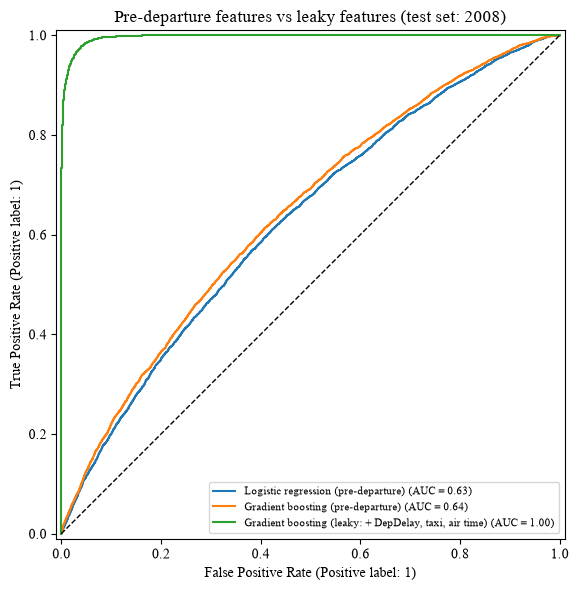

In [64]:
fig, ax = plt.subplots(figsize=(8, 6))
model_v2.plot_roc(fitted_v2, test_v2, ax=ax)
plt.show()

**Reading the result.** With pre-departure information only, gradient boosting scores about 0.64 on this 1% sample (0.654 with the 30% sample used in the README): a modest but real signal. Adding departure delay, taxi and air time pushes it close to 1. That gap is the leakage that inflated Q5a.